In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow import keras
from tensorflow.keras import layers

In [11]:
# Load Credit Card Dataset
df = pd.read_csv('Credit Card Dataset/creditcard.csv')

In [22]:
# 3. Separate input features and target labels
X = df.drop("Class", axis=1)
y = df["Class"]


In [23]:
# 4. Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [24]:
# 5. Select only normal transactions for training
X_train_normal = X_train[y_train == 0]

In [25]:
# 6. Scale the data
scaler = StandardScaler()
X_train_normal = scaler.fit_transform(X_train_normal)
X_test = scaler.transform(X_test)


In [26]:
# 7. Build the Autoencoder model
input_img = keras.Input(shape=(X_train_normal.shape[1],))

# Encoder: Compress the input data
encoded = layers.Dense(16, activation="relu")(input_img)
encoded = layers.Dense(8, activation="relu")(encoded)

# Decoder: Reconstruct the input data
decoded = layers.Dense(16, activation="relu")(encoded)
decoded = layers.Dense(X_train_normal.shape[1])(decoded)

autoencoder = keras.Model(input_img, decoded)

In [27]:
# 8. Compile the model
autoencoder.compile(optimizer="adam", loss="mse")

In [28]:
# 9. Train the Autoencoder using normal transactions
autoencoder.fit(
    X_train_normal, X_train_normal,
    epochs=10,
    batch_size=256,
    shuffle=True
)

Epoch 1/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.8732
Epoch 2/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.6105
Epoch 3/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5512
Epoch 4/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.5195
Epoch 5/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.5162
Epoch 6/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.5027
Epoch 7/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.4967
Epoch 8/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.4828
Epoch 9/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.4799
Epoch 10/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.4773


In [29]:

# 10. Calculate reconstruction error and anomaly threshold
train_reconstructed = autoencoder.predict(X_train_normal)
train_error = np.mean((X_train_normal - train_reconstructed) ** 2, axis=1)

threshold = np.percentile(train_error, 95)
print("Anomaly Threshold:", threshold)

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step
Anomaly Threshold: 1.0105252455710219


In [30]:
# 11. Detect fraud transactions
reconstructed = autoencoder.predict(X_test)
error = np.mean((X_test - reconstructed) ** 2, axis=1)

# Error above threshold is classified as fraud
predictions = (error > threshold).astype(int)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [31]:

# 12. Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions))



Accuracy: 0.948843088374706

Confusion Matrix:
[[53968  2896]
 [   18    80]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     56864
           1       0.03      0.82      0.05        98

    accuracy                           0.95     56962
   macro avg       0.51      0.88      0.51     56962
weighted avg       1.00      0.95      0.97     56962



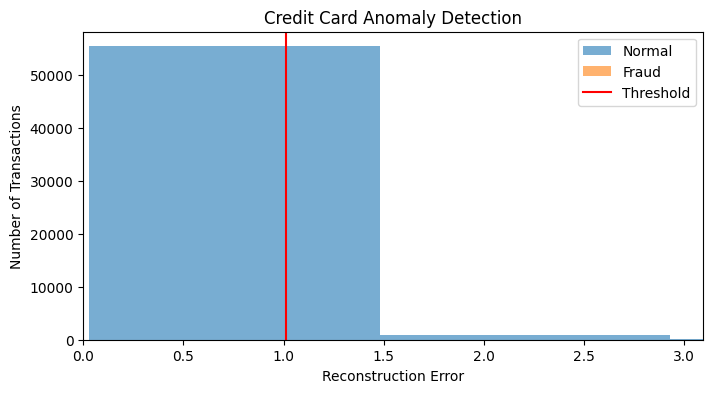

In [32]:
# 13. Display reconstruction error graph
plt.figure(figsize=(8, 4))

plt.hist(error[y_test.values == 0], bins=50,
         alpha=0.6, label="Normal")

plt.hist(error[y_test.values == 1], bins=50,
         alpha=0.6, label="Fraud")

plt.axvline(threshold, color="red", label="Threshold")

plt.xlim(0, np.percentile(error, 99))
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Transactions")
plt.title("Credit Card Anomaly Detection")
plt.legend()
plt.show()

In [ ]:
1. What is an Autoencoder?
An autoencoder is an unsupervised neural network that learns to compress and reconstruct input data. It tries to reproduce the original input.

2. What is anomaly detection?
Anomaly detection is the process of identifying unusual or abnormal data. In this practical, it is used to detect suspicious credit card transactions.

3. Why do we use an Autoencoder for fraud detection?
The autoencoder learns the pattern of normal transactions. Fraud transactions may have higher reconstruction errors because they are different from normal patterns.

4. What is the encoder?
The encoder compresses the input data into a smaller representation. In our code, it reduces the features from 30 to 16 and then to 8.

5. What is the decoder?
The decoder reconstructs the original input from the compressed representation. It expands the data from 8 to 16 and then back to 30 features.

6. What is reconstruction error?
Reconstruction error is the difference between the original input and the reconstructed output. A higher error may indicate an anomaly.

7. What is a threshold?
A threshold is a boundary used to classify transactions. If reconstruction error is greater than the threshold, the transaction is marked as fraud.

8. Why do we train only on normal transactions?
The autoencoder learns the normal transaction pattern. It can then identify transactions that differ significantly from that pattern.

9. What is the purpose of StandardScaler?
StandardScaler scales features to have approximately zero mean and unit variance. This helps the neural network train more effectively.

10. What is the Class column?
The Class column contains the target labels. 0 represents a normal transaction and 1 represents a fraudulent transaction.

11. What is the purpose of train_test_split?
It divides the dataset into training and testing data. Training data is used to build the model, while testing data evaluates it.

12. What is MSE?
MSE stands for Mean Squared Error. It calculates the average squared difference between the original and reconstructed values.

13. Why do we use the ReLU activation function?
ReLU stands for Rectified Linear Unit. It introduces non-linearity and helps the network learn complex patterns.

14. Why do we use the Adam optimizer?
Adam is an optimization algorithm that updates the model weights during training. It helps the model minimize its loss.

15. What is an epoch?
An epoch is one complete pass through the training dataset. In our code, the autoencoder is trained for 10 epochs.

16. What is batch size?
Batch size is the number of training samples processed before updating the model weights. In our code, the batch size is 256.

17. What is the purpose of the 95th percentile?
It sets the anomaly threshold using the reconstruction errors of normal training transactions. Errors above this threshold are marked as possible fraud.

18. What is a confusion matrix?
A confusion matrix compares actual labels with predicted labels. It shows correct and incorrect predictions for each class.

19. What is precision and recall?
Precision measures how many predicted fraud transactions are actually fraud. Recall measures how many actual fraud transactions the model successfully detects.

20. What is the main advantage of an Autoencoder?
It can learn normal data patterns without needing fraud examples during training. It can identify unusual transactions using reconstruction error.